In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# Step 1: Install necessary libraries
!pip install tensorflow
!pip install pandas
!pip install scikit-learn
!pip install matplotlib


Column Names: Index(['Date', 'Label', 'Top1', 'Top2', 'Top3', 'Top4', 'Top5', 'Top6', 'Top7',
       'Top8', 'Top9', 'Top10', 'Top11', 'Top12', 'Top13', 'Top14', 'Top15',
       'Top16', 'Top17', 'Top18', 'Top19', 'Top20', 'Top21', 'Top22', 'Top23',
       'Top24', 'Top25'],
      dtype='object')
50/50 [==============================] - 2s 50ms/step - loss: 0.6905 - accuracy: 0.5399 - val_loss: 0.6933 - val_accuracy: 0.5176


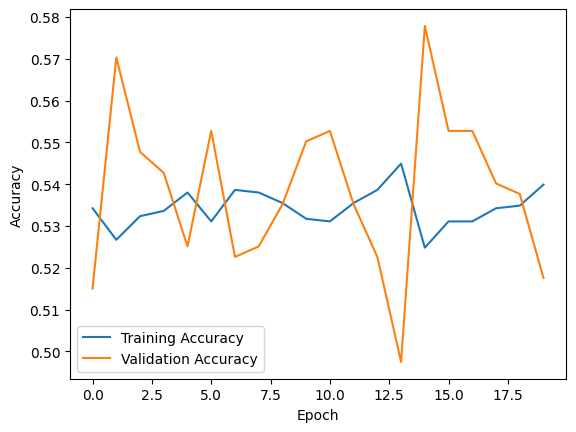

In [19]:
# Step 2: Import libraries
import pandas as pd
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Replace 'your_dataset.csv' with your actual file path
df = pd.read_csv('Combined_News_DJIA.csv')

# Print the column names to identify the correct names
print("Column Names:", df.columns)

# Step 4: Explore and preprocess the dataset
# Assuming your dataset has different column names, replace 'text' and 'label' with the actual column names
X = df['Top25']
y = df['Label']

# Handle missing values by replacing NaN with an empty string
X = X.fillna("")

# Step 5: Tokenize and pad sequences
tokenizer = Tokenizer(num_words=5000, oov_token="<OOV>")
tokenizer.fit_on_texts(X)
X_sequences = tokenizer.texts_to_sequences(X)
X_padded = pad_sequences(X_sequences, maxlen=100, padding='post', truncating='post')

# Step 7: Build and compile the RNN model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=5000, output_dim=16, input_length=100),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Initialize lists to store accuracy values for each epoch
train_acc_list = []
val_acc_list = []

# Step 8: Train the model with 20 epochs
for epoch in range(20):
    # Split the dataset into training and testing sets for each epoch
    X_train, X_test, y_train, y_test = train_test_split(X_padded, y, test_size=0.2, random_state=epoch * 42)

    # Train the model
    history = model.fit(X_train, y_train, epochs=1, validation_data=(X_test, y_test))

    # Append accuracy values to the lists
    train_acc_list.append(history.history['accuracy'][0])
    val_acc_list.append(history.history['val_accuracy'][0])

# Step 9: Plot the accuracy graph
plt.plot(train_acc_list, label='Training Accuracy')
plt.plot(val_acc_list, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()


In [22]:
# Calculate average accuracy
average_train_accuracy = sum(train_acc_list) / len(train_acc_list)
average_val_accuracy = sum(val_acc_list) / len(val_acc_list)

# Print average accuracies
print(f'Average Training Accuracy: {average_train_accuracy:.4f}')
print(f'Average Validation Accuracy: {average_val_accuracy:.4f}')


Average Training Accuracy: 0.5321
Average Validation Accuracy: 0.5440
